# **PUMP IT UP 2 - JAIME DE VERA MARTÍN**

---

---



## Me conecto a Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Importo las librerías necesarias

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import TargetEncoder

from sklearn.metrics import classification_report, accuracy_score

## Me creo mis DataFrames principales

In [3]:
X_train_original = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/Tarea/Conjuntos de datos/TrainingSetValues.csv',
                          sep=',',
                          index_col='id',
                          parse_dates=['date_recorded'])

y_train_original = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/Tarea/Conjuntos de datos/TrainingSetLabels.csv',
                          sep=',',
                          index_col='id')

X_test_original = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/Tarea/Conjuntos de datos/TestSetValues.csv',
                          sep=',',
                          index_col='id',
                          parse_dates=['date_recorded'])

# Mapeo de la variable objetivo a formato numérico
y = y_train_original["status_group"].map({'non functional': 0, 'functional needs repair': 1, 'functional': 2})

print(f"Dimensiones de entrenamiento original: {X_train_original.shape}")

Dimensiones de entrenamiento original: (59400, 39)


## **LIMPIEZA**


In [4]:
def preprocesado_estructural(df):
    df_clean = df.copy()

    # Ingeniería de fechas
    df_clean['antiguedad'] = df_clean['date_recorded'].dt.year - df_clean['construction_year']
    df_clean.drop(columns=['date_recorded', 'construction_year'], inplace=True)

    # Eliminación de redundancias y alta cardinalidad
    columnas_a_borrar = [
        'recorded_by', 'num_private', 'wpt_name', 'scheme_name',
        'subvillage', 'ward', 'lga',
        'extraction_type_group', 'extraction_type_class',
        'management_group', 'scheme_management',
        'payment_type', 'quality_group', 'quantity_group',
        'source_type', 'source_class', 'waterpoint_type_group',
        'funder', 'installer']

    df_clean.drop(columns=columnas_a_borrar, inplace=True, errors='ignore')

    # Reemplazar ceros y outliers
    columnas_con_ceros = ['longitude', 'population', 'gps_height']
    df_clean[columnas_con_ceros] = df_clean[columnas_con_ceros].replace(0, np.nan)
    df_clean['antiguedad'] = df_clean['antiguedad'].apply(lambda x: np.nan if x > 100 else x)

    return df_clean

# Aplicamos la función a nuestros datos de entrenamiento
X_clean = preprocesado_estructural(X_train_original)

print(f"Dimensiones tras limpieza estructural: {X_clean.shape}")

Dimensiones tras limpieza estructural: (59400, 19)


## **AUTOMATIZACIÓN DE MODELADO (PIPELINE & GRIDSEARCHCV)**

In [5]:
# Separación del conjunto de validación
X_train, X_val, y_train, y_val = train_test_split(X_clean, y, test_size=0.2, random_state=42, stratify=y)

# Identificación dinámica de tipos de variables
num_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

# Construcción de transformadores
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)])

# Configuración de modelos e hiperparámetros
models = {
    'DecisionTree': DecisionTreeClassifier(random_state=42),
    'RandomForest': RandomForestClassifier(random_state=42)}

param_grid = {
    'DecisionTree': {
        'classifier__max_depth': [10, None],},
    'RandomForest': {
        'classifier__n_estimators': [100, 200],
        'classifier__max_depth': [20, None],
        'classifier__min_samples_split': [2, 5]}}

# Ejecución del GridSearchCV
best_models = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)])

    grid_search = GridSearchCV(pipeline, param_grid[name], cv=3, scoring='accuracy', n_jobs=-1, verbose=3)
    grid_search.fit(X_train, y_train)

    best_models[name] = grid_search.best_estimator_
    print(f"{name} optimizado:")
    print(f"Mejores parámetros: {grid_search.best_params_}")
    print(f"Score en CV: {grid_search.best_score_:.4f}\n")

# Evaluación contra el set de validación
print("-" * 40)
print("EVALUACIÓN FINAL EN VALIDACIÓN:")
for name, model in best_models.items():
    test_score = model.score(X_val, y_val)
    print(f"Precisión para {name}: {test_score:.4f}")
print("-" * 40)

Fitting 3 folds for each of 2 candidates, totalling 6 fits
DecisionTree optimizado:
Mejores parámetros: {'classifier__max_depth': None}
Score en CV: 0.7435

Fitting 3 folds for each of 8 candidates, totalling 24 fits
RandomForest optimizado:
Mejores parámetros: {'classifier__max_depth': 20, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Score en CV: 0.8018

----------------------------------------
EVALUACIÓN FINAL EN VALIDACIÓN:
Precisión para DecisionTree: 0.7608
Precisión para RandomForest: 0.8110
----------------------------------------


## **INTERPRETABILIDAD DEL MODELADO AUTOMATIZADO**

Al utilizar un `Pipeline` con `ColumnTransformer`, el modelo ha generado columnas nuevas con One-Hot Encoding. Para ver la importancia de las variables, debemos extraer los nombres exactos de las características matemáticas que el Pipeline creó y cruzarlas con los pesos del Random Forest.

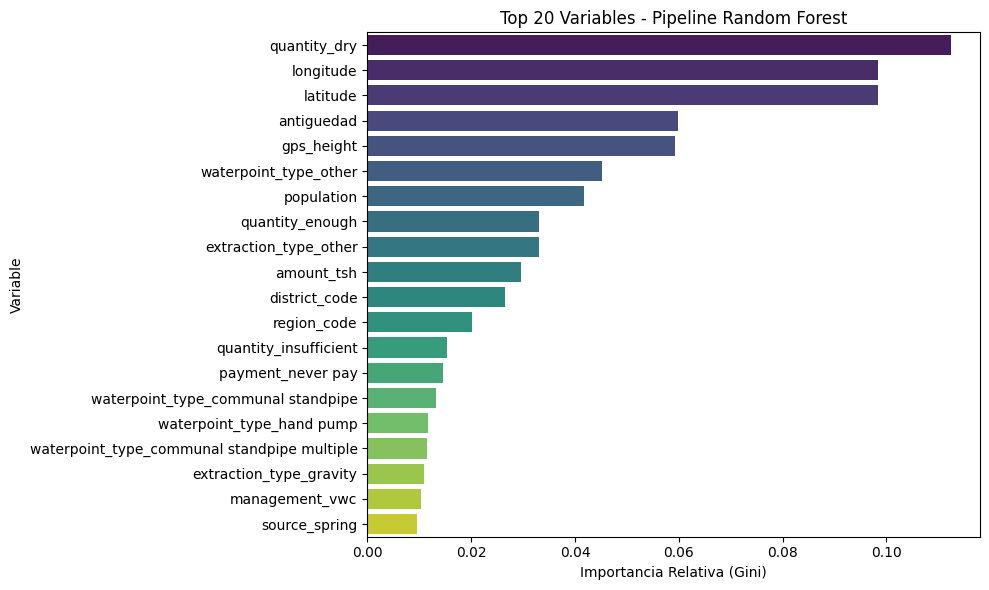

In [6]:
mejor_pipeline_rf = best_models['RandomForest']

preprocesador = mejor_pipeline_rf.named_steps['preprocessor']
modelo_rf = mejor_pipeline_rf.named_steps['classifier']

nombres_num = num_features

ohe = preprocesador.named_transformers_['cat'].named_steps['onehot']
nombres_cat = ohe.get_feature_names_out(cat_features)

nombres_columnas_finales = nombres_num + list(nombres_cat)

importancias = modelo_rf.feature_importances_

df_importancias_pipe = pd.DataFrame({
    'Variable': nombres_columnas_finales,
    'Importancia': importancias}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=df_importancias_pipe.head(20), palette='viridis', hue='Variable', legend=False)
plt.title('Top 20 Variables - Pipeline Random Forest')
plt.xlabel('Importancia Relativa (Gini)')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

## **PREDICCIÓN Y EXPORTACIÓN**

In [7]:
X_test_clean = preprocesado_estructural(X_test_original)

predicciones_numericas = mejor_pipeline_rf.predict(X_test_clean)

mapeo_inverso = {0: 'non functional', 1: 'functional needs repair', 2: 'functional'}
predicciones_texto = pd.Series(predicciones_numericas).map(mapeo_inverso)

df_submission_v2 = pd.DataFrame({
    'id': X_test_original.index,
    'status_group': predicciones_texto})

nombre_archivo_v2 = 'pipeline_v2_submission.csv'
#df_submission_v2.to_csv(nombre_archivo_v2, index=False)

df_submission_v2.head(5)

,id,status_group
0,50785,non functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional


## **INTENTO DE MEJORA DEL MODELO 1: TARGET ENCODING**


Después de eliminar varias columnas que pueden ser relevantes, vamos a rescatarlas. Con el **Target Encoding** sustituiremos el texto por la probabilidad matemática histórica de que los pozos funcionen. Transformaremos miles de columnas ruidosas en dos columnas numéricas.

In [10]:
# Volvemos a partir de los datos originales, pero esta vez con funder e installer
X_clean_target = X_train_original.copy()

# Ingeniería de fechas
X_clean_target['antiguedad'] = X_clean_target['date_recorded'].dt.year - X_clean_target['construction_year']
X_clean_target.drop(columns=['date_recorded', 'construction_year'], inplace=True)

# Borramos redundancias, pero salvamos a los culpables de la alta cardinalidad
columnas_borrar_target = [
    'recorded_by', 'num_private', 'wpt_name', 'scheme_name',
    'subvillage', 'ward', 'lga', 'extraction_type_group', 'extraction_type_class',
    'management_group', 'scheme_management', 'payment_type', 'quality_group', 'quantity_group',
    'source_type', 'source_class', 'waterpoint_type_group']

X_clean_target.drop(columns=columnas_borrar_target, inplace=True, errors='ignore')

# Reemplazo de ceros
for col in ['longitude', 'population', 'gps_height']:
    X_clean_target[col] = X_clean_target[col].replace(0, np.nan)
X_clean_target['antiguedad'] = X_clean_target['antiguedad'].apply(lambda x: np.nan if x > 100 else x)

# Separación de datos
X_train_te, X_val_te, y_train_te, y_val_te = train_test_split(X_clean_target, y, test_size=0.2, random_state=42, stratify=y)

num_features_te = X_train_te.select_dtypes(include=[np.number]).columns.tolist()
cat_high_cardinality = ['funder', 'installer']
cat_low_cardinality = [col for col in X_train_te.select_dtypes(exclude=[np.number]).columns if col not in cat_high_cardinality]

# Transformador numérico
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

# One-Hot
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])

# Target Encoder
target_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('target_enc', TargetEncoder(smooth="auto"))])

# Ensamblamos todo en el ColumnTransformer
preprocessor_te = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features_te),
        ('cat_low', cat_transformer, cat_low_cardinality),
        ('cat_high', target_transformer, cat_high_cardinality)])

modelo_rf_te = Pipeline(steps=[
    ('preprocessor', preprocessor_te),
    ('classifier', RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42, n_jobs=-1))])

modelo_rf_te.fit(X_train_te, y_train_te)

# Evaluación
score_te = modelo_rf_te.score(X_val_te, y_val_te)
print("-" * 40)
print(f"PRECISION CON TARGET ENCODING: {score_te * 100:.2f}%")
print("-" * 40)

----------------------------------------
PRECISION CON TARGET ENCODING: 80.70%
----------------------------------------


## **INTERPRETABILIDAD TARGET ENCODING**

Columas generadas: 115 | Pesos del modelo: 115


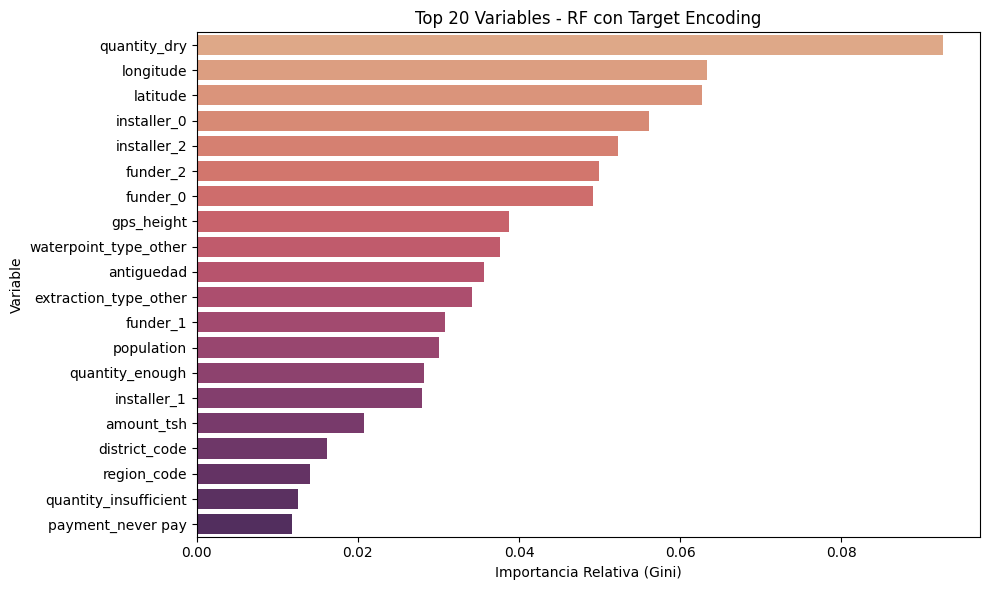

Las 5 variables más importantes ahora son: ['quantity_dry', 'longitude', 'latitude', 'installer_0', 'installer_2']


In [13]:
preprocesador_te = modelo_rf_te.named_steps['preprocessor']
rf_te = modelo_rf_te.named_steps['classifier']

nombres_crudos = preprocesador_te.get_feature_names_out()

nombres_columnas_te = [nombre.split('__')[-1] for nombre in nombres_crudos]

importancias_te = rf_te.feature_importances_

print(f"Columas generadas: {len(nombres_columnas_te)} | Pesos del modelo: {len(importancias_te)}")

df_importancias_te = pd.DataFrame({
    'Variable': nombres_columnas_te,
    'Importancia': importancias_te}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=df_importancias_te.head(20), palette='flare', hue='Variable', legend=False)
plt.title('Top 20 Variables - RF con Target Encoding')
plt.xlabel('Importancia Relativa (Gini)')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

top5_te = df_importancias_te['Variable'].head(5).tolist()
print(f"Las 5 variables más importantes ahora son: {top5_te}")

## **PREDICCIÓN Y EXPORTACIÓN TARGET ENCODING**

In [14]:
X_test_te = X_test_original.copy()

X_test_te['antiguedad'] = X_test_te['date_recorded'].dt.year - X_test_te['construction_year']
X_test_te.drop(columns=['date_recorded', 'construction_year'], inplace=True)
X_test_te.drop(columns=columnas_borrar_target, inplace=True, errors='ignore')

for col in ['longitude', 'population', 'gps_height']:
    X_test_te[col] = X_test_te[col].replace(0, np.nan)
X_test_te['antiguedad'] = X_test_te['antiguedad'].apply(lambda x: np.nan if x > 100 else x)

predicciones_num_te = modelo_rf_te.predict(X_test_te)

mapeo_inverso = {0: 'non functional', 1: 'functional needs repair', 2: 'functional'}
predicciones_texto_te = pd.Series(predicciones_num_te).map(mapeo_inverso)

df_submission_te = pd.DataFrame({
    'id': X_test_original.index,
    'status_group': predicciones_texto_te})

nombre_archivo_te = 'target_encoding_v2_submission.csv'
#df_submission_te.to_csv(nombre_archivo_te, index=False)

df_submission_te.head(5)

Archivo exportado exitosamente: v2_target_encoding_submission.csv


,id,status_group
0,50785,functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional


## **INTENTO DE MEJORA 2: CLASS IMBALANCE**

Hasta ahora hemos medido el éxito con la Accuracy. Sin embargo, el dataset está fuertemente desbalanceado: los pozos que necesitan reparación son una gran minoría (7%). El modelo tiende a ignorarlos para maximizar su precisión general, lo cual es muy malo para el negocio, ya que el mantenimiento preventivo puede ahorrar mucho dinero frente a la reconstrucción total.

Para solucionarlo, utilizaremos el balanceo de clases automático (`class_weight='balanced'`). Esto obliga matemáticamente al Random Forest a penalizar mucho más los errores cometidos sobre las clases minoritarias, forzándole a prestarles atención. Evaluaremos el resultado con un Reporte de Clasificación para ver el Recall.

In [19]:
# Utilizamos el mismo preprocesador con Target Encoding con class_weight='balanced'
modelo_rf_final = Pipeline(steps=[
    ('preprocessor', preprocessor_te),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        random_state=42,
        n_jobs=-1,
        class_weight='balanced'))])

# Entrenamos
modelo_rf_final.fit(X_train_te, y_train_te)

# Predicciones
predicciones_finales = modelo_rf_final.predict(X_val_te)

# Evaluación
print("\n" + "=" * 60)
print("REPORTE DE CLASIFICACIÓN")
print("=" * 60)
nombres_clases = ['non functional', 'functional needs repair', 'functional']
print(classification_report(y_val_te, predicciones_finales, target_names=nombres_clases))

# Accuracy final
score_final = accuracy_score(y_val_te, predicciones_finales)
print("-" * 60)
print(f"Accuracy: {score_final * 100:.2f}%")
print("-" * 60)


REPORTE DE CLASIFICACIÓN
                         precision    recall  f1-score   support

         non functional       0.85      0.76      0.80      4565
functional needs repair       0.41      0.51      0.45       863
             functional       0.81      0.85      0.83      6452

               accuracy                           0.79     11880
              macro avg       0.69      0.71      0.70     11880
           weighted avg       0.80      0.79      0.79     11880

------------------------------------------------------------
Accuracy: 79.14%
------------------------------------------------------------


## **INTERPRETABILIDAD CLASS IMBALANCE**

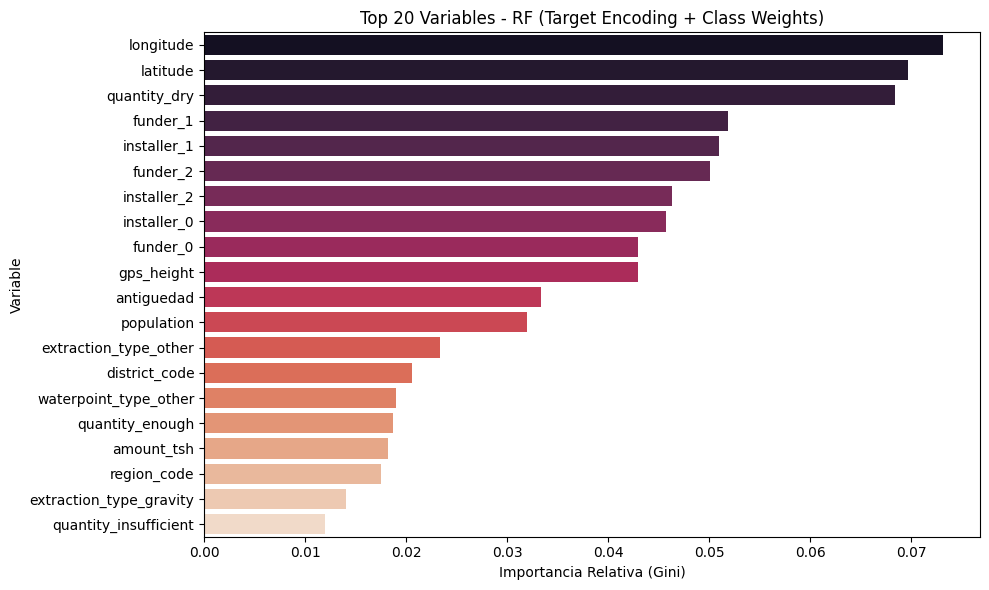

Comparativa rápida con el modelo anterior:
Top 3 Anterior: ['quantity_dry', 'longitude', 'latitude']
Top 3 Actual:   ['longitude', 'latitude', 'quantity_dry']


In [20]:
rf_final = modelo_rf_final.named_steps['classifier']

importancias_finales = rf_final.feature_importances_

df_importancias_final = pd.DataFrame({
    'Variable': nombres_columnas_te,
    'Importancia': importancias_finales}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importancia',
    y='Variable',
    data=df_importancias_final.head(20),
    palette='rocket',
    hue='Variable',
    legend=False)
plt.title('Top 20 Variables - RF (Target Encoding + Class Weights)')
plt.xlabel('Importancia Relativa (Gini)')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

print("Comparativa rápida con el modelo anterior:")
print(f"Top 3 Anterior: {top5_te[:3]}")
print(f"Top 3 Actual:   {df_importancias_final['Variable'].head(3).tolist()}")

## **PREDICCIÓN Y EXPORTACIÓN CLASS IMBALANCE**

In [21]:
predicciones_num_ci = modelo_rf_final.predict(X_test_te)

predicciones_texto_ci = pd.Series(predicciones_num_ci).map(mapeo_inverso)

df_submission_ci = pd.DataFrame({
    'id': X_test_original.index,
    'status_group': predicciones_texto_ci})

nombre_archivo_ci = 'class_imbalance_v2_submission.csv'
#df_submission_ci.to_csv(nombre_archivo_ci, index=False)

df_submission_ci.head(5)

,id,status_group
0,50785,functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional
